## Часть B: StyleGAN-подобная модель

Задача: реализовать упрощённую StyleGAN-like архитектуру (generator + discriminator + mapping network), обучить её на выбранном домене (здесь — тот же датасет лиц CelebA) и показать:

- генерацию новых изображений;
- интерполяцию в latent space;
- style mixing (управляемое комбинирование стилей).

Архитектуры должны быть реализованы самостоятельно, без использования готовых реализаций. Ноутбук сдаётся **с выполненными ячейками**.

**Про вычислительные ресурсы.** Эталонные картинки ниже получены на 128×128 примерно за 70 эпох с R1-регуляризацией: это больше 14 часов на GPU. Такого качества мы не ждём. Можно обучать на 64×64 и меньше эпох — оценивается корректность реализации и разбор результатов, а не фотореалистичность.

*По желанию:* посчитайте FID (как на семинаре) для нескольких чекпойнтов и сравните с тем, что видно глазами.

**План эксперимента.** CelebA, 64×64, обучение с нуля. Свои mapping network, стилизованные блоки AdaIN и noise injection, генератор и дискриминатор. R1, EMA и style-mixing regularization включены в обучение. Все результаты части B сохраняются в `results/stylegan`, веса — в `checkpoints/stylegan`, отдельный run — в `runs/stylegan_*`. Части A и B выполняются независимо; общий кэш содержит только изображения после crop/resize. Референсы из шаблона ниже помечены как референсы и не являются результатами этого обучения.


### Часть B. Шаг 1: Настройка TensorBoard и гиперпараметров для GAN

Что сделать: создать `SummaryWriter` для StyleGAN-подобной модели и задать базовые гиперпараметры.

Ожидается: отдельный лог для GAN и разумные параметры обучения.

In [1]:
import os, math, random, json, time, copy
from pathlib import Path
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import transforms
from torchvision.utils import make_grid, save_image
from torch.utils.tensorboard import SummaryWriter

SEED = 123
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(8)
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
latent_dim_gan, w_dim, num_channels = 128, 128, 3
result_dir = Path('results/stylegan')
checkpoint_dir = Path('checkpoints/stylegan')
for p in [result_dir, checkpoint_dir, Path('data/cache')]: p.mkdir(parents=True, exist_ok=True)
resume_path = checkpoint_dir/'training_last.pth'
resume_state = None
if os.environ.get('STYLEGAN_RESUME','1') == '1' and resume_path.exists():
    resume_state = torch.load(resume_path,map_location='cpu',weights_only=False)
    log_dir_stylegan = resume_state['config']['log_dir']
    print('Продолжение после эпохи',resume_state['epoch'])
else:
    log_dir_stylegan = str(Path('runs') / datetime.now().strftime('stylegan_%Y%m%d_%H%M%S'))
writer_gan = SummaryWriter(log_dir_stylegan,purge_step=resume_state['global_step'] if resume_state else None)
print('Устройство:', device, torch.cuda.get_device_name(device) if device.type == 'cuda' else '')
print('TensorBoard:', Path(log_dir_stylegan).resolve())
print('Seed фиксирует генераторы; cudnn.benchmark не гарантирует побитовую повторяемость.')


Продолжение после эпохи 3


Устройство: cuda:0 NVIDIA A100-SXM4-80GB
TensorBoard: /home/edu/adpak/gen_cv/runs/stylegan_20261126_030716
Seed фиксирует генераторы; cudnn.benchmark не гарантирует побитовую повторяемость.


### Часть B. Шаг 2: Загрузка и предобработка датасета лиц

Что сделать: задать трансформации (crop, resize, normalize), создать датасет CelebA и `DataLoader`.

**Где взять данные.** Нужна версия *Align&Cropped* (`img_align_celeba`, ~200 тыс. изображений 178×218) и файлы разметки. Источники: официальная страница https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html или зеркало на Kaggle `jessicali9530/celeba-dataset`. Автоскачивание `torchvision.datasets.CelebA(download=True)` часто падает из-за лимитов Google Drive.

Положите всё в одну папку:

```
data/celeba/CelebA/
├── img_align_celeba/        # 000001.jpg, 000002.jpg, ...
├── list_attr_celeba.txt     # или list_attr_celeba.csv (Kaggle)
└── list_eval_partition.txt  # или list_eval_partition.csv (Kaggle)
```

Ниже дан готовый класс `CelebAWithAttrs`: он читает и `.txt`, и `.csv` и сам находит вложенную папку `img_align_celeba/img_align_celeba` из архива Kaggle. Датасет возвращает пары `(image, attrs)`, атрибуты приведены к значениям **{0, 1}** (в исходных файлах {−1, 1}). Также доступны `dataset.attr_names` (список из 40 имён) и `dataset.attr` (тензор `[N, 40]`). Последующие ячейки ноутбука рассчитаны именно на этот интерфейс.

Ожидается: корректный `DataLoader` с батчами `(images, attrs)`.

In [2]:
import csv
from pathlib import Path

from PIL import Image
from torch.utils.data import Dataset


class CelebAWithAttrs(Dataset):
    """CelebA (Align&Cropped) с атрибутами.

    root — папка, где лежат img_align_celeba/ и файлы разметки (.txt или .csv).
    split — 'train', 'valid', 'test' или 'all' (по list_eval_partition).
    Возвращает (image, attrs), attrs — float-тензор из 0 и 1 длины 40.
    """

    SPLITS = {"train": 0, "valid": 1, "test": 2}

    def __init__(self, root, split="train", transform=None):
        root = Path(root)
        self.transform = transform

        img_dir = root / "img_align_celeba"
        if (img_dir / "img_align_celeba").is_dir():  # архив с Kaggle
            img_dir = img_dir / "img_align_celeba"
        if not img_dir.is_dir():
            raise FileNotFoundError(f"Не найдена папка с изображениями: {img_dir}")
        self.img_dir = img_dir

        self.attr_names, attrs = self._read_attrs(root)
        partition = self._read_partition(root)

        if split == "all":
            files = list(attrs)
        else:
            files = [f for f in attrs if partition[f] == self.SPLITS[split]]
        self.filenames = files
        self.attr = torch.tensor([attrs[f] for f in files], dtype=torch.long)
        self.attr = (self.attr + 1) // 2  # {-1, 1} -> {0, 1}

    @staticmethod
    def _read_attrs(root):
        txt, csv_path = root / "list_attr_celeba.txt", root / "list_attr_celeba.csv"
        attrs = {}
        if txt.exists():
            with open(txt) as f:
                lines = f.read().splitlines()
            names = lines[1].split()
            for line in lines[2:]:
                parts = line.split()
                attrs[parts[0]] = [int(v) for v in parts[1:]]
        elif csv_path.exists():
            with open(csv_path) as f:
                reader = csv.reader(f)
                names = next(reader)[1:]
                for row in reader:
                    attrs[row[0]] = [int(v) for v in row[1:]]
        else:
            raise FileNotFoundError(f"Не найден list_attr_celeba.txt/.csv в {root}")
        return names, attrs

    @staticmethod
    def _read_partition(root):
        txt, csv_path = root / "list_eval_partition.txt", root / "list_eval_partition.csv"
        if txt.exists():
            with open(txt) as f:
                return {p[0]: int(p[1]) for p in (l.split() for l in f) if p}
        if csv_path.exists():
            with open(csv_path) as f:
                reader = csv.reader(f)
                next(reader)
                return {row[0]: int(row[1]) for row in reader}
        raise FileNotFoundError(f"Не найден list_eval_partition.txt/.csv в {root}")

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        image = Image.open(self.img_dir / self.filenames[idx]).convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, self.attr[idx].float()

Train: 162770; valid: 19867; батчей: 1271
Атрибуты не используются как условия GAN; домен — все лица CelebA train.


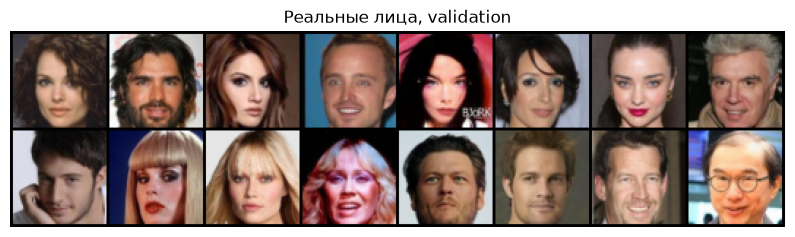

In [3]:
image_size, batch_size = 64, 128
root = Path(os.environ.get('CELEBA_ROOT', 'data/celeba/CelebA'))
transform = transforms.Compose([
    transforms.CenterCrop(140), transforms.Resize(image_size, antialias=True),
    transforms.ToTensor(), transforms.Normalize([0.5]*3, [0.5]*3),
])
base_train = CelebAWithAttrs(root, 'train', transform)
base_valid = CelebAWithAttrs(root, 'valid', transform)
assert set(base_train.filenames).isdisjoint(base_valid.filenames)
# Кэш содержит только crop/resize, без случайного отражения.
all_faces = CelebAWithAttrs(root, 'all', transforms.Compose([
    transforms.CenterCrop(140), transforms.Resize(image_size, antialias=True), transforms.PILToTensor(),
]))
cache_path = Path('data/cache/celeba_crop140_64_uint8.npy')
if not cache_path.exists():
    tmp = cache_path.with_suffix('.partial.npy')
    out = np.lib.format.open_memmap(tmp, mode='w+', dtype='uint8',
                                   shape=(len(all_faces), 3, image_size, image_size))
    offset = 0
    for images, _ in DataLoader(all_faces, batch_size=512, num_workers=8):
        out[offset:offset+len(images)] = images.numpy(); offset += len(images)
    out.flush(); del out; tmp.replace(cache_path)
cache = np.load(cache_path, mmap_mode='r')
assert cache.shape == (len(all_faces), 3, image_size, image_size)
name_to_index = {name:i for i,name in enumerate(all_faces.filenames)}
class CachedCelebA(Dataset):
    def __init__(self, source):
        self.filenames, self.attr_names, self.attr = source.filenames, source.attr_names, source.attr
        self.indices = np.array([name_to_index[f] for f in self.filenames])
    def __len__(self): return len(self.filenames)
    def __getitem__(self, i):
        x = torch.from_numpy(np.array(cache[self.indices[i]], copy=True))
        return x.float().div_(127.5).sub_(1), self.attr[i].float()
dataset = CachedCelebA(base_train)
valid_dataset = CachedCelebA(base_valid)
loader_generator = torch.Generator().manual_seed(SEED)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, drop_last=True,
                        num_workers=8, persistent_workers=True, pin_memory=True,
                        generator=loader_generator)
# Последний неполный батч отбрасываем; shuffle меняет эти примеры каждую эпоху.
valid_images = torch.stack([valid_dataset[i][0] for i in range(128)]).to(device)
print(f'Train: {len(dataset)}; valid: {len(valid_dataset)}; батчей: {len(dataloader)}')
print('Атрибуты не используются как условия GAN; домен — все лица CelebA train.')
plt.figure(figsize=(10, 3))
plt.imshow(make_grid((valid_images[:16].cpu()+1)/2, nrow=8).permute(1,2,0))
plt.axis('off'); plt.title('Реальные лица, validation'); plt.show()


### Часть B. Шаг 3: Реализация генератора, дискриминатора и mapping-сети

Что сделать: реализовать классы `MappingNetwork`, `StyledBlock`, `StyleGenerator` и `StyleDiscriminator`.

**Обязательный интерфейс** (на него рассчитаны шаги 5 и 6):

- латентный вектор `z` имеет форму `[B, latent_dim_gan]` (двумерный, без `1×1`);
- `G.mapping(z)` → `w` формы `[B, w_dim]`;
- `G.num_ws` — число стилевых входов синтеза (по одному на `StyledBlock`), не меньше 4;
- `G.make_ws(z)` → `ws` формы `[B, G.num_ws, w_dim]` (один и тот же `w`, повторённый `num_ws` раз);
- `G.forward_from_ws(ws)` → изображения `[B, 3, image_size, image_size]` в `[-1, 1]`; блок `i` использует `ws[:, i]`;
- `G(z)` = `G.forward_from_ws(G.make_ws(z))`;
- `D(x)` → логиты формы `[B, 1]`.

Ожидается: рабочая генерация изображений заданного размера.

In [4]:
class EqualLinear(nn.Module):
    def __init__(self, in_dim, out_dim, gain=1.0, lr_mul=1.0):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(out_dim, in_dim) / lr_mul)
        self.bias = nn.Parameter(torch.zeros(out_dim))
        self.scale, self.lr_mul = gain / math.sqrt(in_dim) * lr_mul, lr_mul
    def forward(self, x):
        return F.linear(x, self.weight * self.scale, self.bias * self.lr_mul)

class EqualConv2d(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size=3, gain=math.sqrt(2)):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(out_ch, in_ch, kernel_size, kernel_size))
        self.bias = nn.Parameter(torch.zeros(out_ch))
        self.scale = gain / math.sqrt(in_ch * kernel_size**2)
        self.padding = kernel_size // 2
    def forward(self, x):
        return F.conv2d(x, self.weight * self.scale, self.bias, padding=self.padding)

class Blur(nn.Module):
    def __init__(self):
        super().__init__()
        k = torch.tensor([1., 2., 1.]); k = k[:, None] * k[None, :]
        self.register_buffer('kernel', (k/k.sum())[None, None])
    def forward(self, x):
        return F.conv2d(x, self.kernel.expand(x.shape[1],1,3,3), padding=1, groups=x.shape[1])

class MappingNetwork(nn.Module):
    """Нормализация z + четыре fully connected слоя: Z -> W."""
    def __init__(self, z_dim, w_dim):
        super().__init__()
        self.layers = nn.ModuleList([
            EqualLinear(z_dim if i == 0 else w_dim, w_dim, gain=math.sqrt(2), lr_mul=0.01)
            for i in range(4)])
    def forward(self, z):
        x = z * torch.rsqrt(z.square().mean(1, keepdim=True) + 1e-8)
        for layer in self.layers: x = F.leaky_relu(layer(x), 0.2)
        return x

class StyledBlock(nn.Module):
    """Conv + noise + LeakyReLU + AdaIN(w); один стилевой вход на блок."""
    def __init__(self, in_channels, out_channels, w_dim, resolution=4, upsample=False):
        super().__init__()
        self.upsample, self.blur = upsample, Blur()
        self.conv = EqualConv2d(in_channels, out_channels)
        self.noise_strength = nn.Parameter(torch.zeros(1, out_channels, 1, 1))
        self.register_buffer('noise_const', torch.randn(1, 1, resolution, resolution))
        self.affine = EqualLinear(w_dim, 2*out_channels)
        with torch.no_grad():
            self.affine.weight.mul_(0.1)
            self.affine.bias[:out_channels].fill_(1)
    def forward(self, x, w, noise_mode='const'):
        if self.upsample: x = self.blur(F.interpolate(x, scale_factor=2, mode='nearest'))
        x = self.conv(x)
        if noise_mode == 'random':
            noise = torch.randn(x.shape[0], 1, x.shape[2], x.shape[3], device=x.device, dtype=x.dtype)
        elif noise_mode == 'const': noise = self.noise_const
        elif noise_mode == 'none': noise = 0
        else: raise ValueError(noise_mode)
        x = F.leaky_relu(x + self.noise_strength * noise, 0.2)
        x = (x - x.mean((2,3), keepdim=True)) * torch.rsqrt(x.var((2,3), unbiased=False, keepdim=True) + 1e-8)
        scale, bias = self.affine(w).chunk(2, dim=1)
        return x * scale[:, :, None, None] + bias[:, :, None, None]

class StyleGenerator(nn.Module):
    def __init__(self, z_dim, w_dim, img_channels=3):
        super().__init__()
        self.mapping = MappingNetwork(z_dim, w_dim)
        self.constant = nn.Parameter(torch.randn(1, 256, 4, 4))
        self.register_buffer('w_avg', torch.zeros(w_dim))
        blocks, in_ch = [], 256
        for resolution, out_ch in [(4,256),(8,256),(16,128),(32,64),(64,32)]:
            blocks += [StyledBlock(in_ch,out_ch,w_dim,resolution,upsample=resolution>4),
                       StyledBlock(out_ch,out_ch,w_dim,resolution)]
            in_ch = out_ch
        self.blocks = nn.ModuleList(blocks)
        self.num_ws = len(blocks)
        self.to_rgb = EqualConv2d(in_ch,img_channels,1,gain=1)
    def make_ws(self, z):
        return self.mapping(z)[:,None,:].repeat(1,self.num_ws,1)
    def forward_from_ws(self, ws, noise_mode='const'):
        x = self.constant.expand(ws.shape[0],-1,-1,-1)
        for i,block in enumerate(self.blocks): x = block(x,ws[:,i],noise_mode)
        return torch.tanh(self.to_rgb(x))
    def forward(self,z,noise_mode='const'):
        return self.forward_from_ws(self.make_ws(z),noise_mode)

class DiscriminatorBlock(nn.Module):
    def __init__(self,in_ch,out_ch):
        super().__init__()
        self.conv1, self.conv2 = EqualConv2d(in_ch,in_ch), EqualConv2d(in_ch,out_ch)
        self.skip = EqualConv2d(in_ch,out_ch,1,gain=1)
        self.blur = Blur()
    def forward(self,x):
        residual = self.skip(F.avg_pool2d(self.blur(x),2))
        h = F.leaky_relu(self.conv1(x),0.2)
        h = F.avg_pool2d(self.blur(F.leaky_relu(self.conv2(h),0.2)),2)
        return (h+residual)/math.sqrt(2)

class StyleDiscriminator(nn.Module):
    def __init__(self,img_channels=3):
        super().__init__()
        self.from_rgb = EqualConv2d(img_channels,32,1)
        self.blocks = nn.Sequential(*[DiscriminatorBlock(a,b) for a,b in [(32,64),(64,128),(128,256),(256,256)]])
        self.final_conv = EqualConv2d(257,256)
        self.fc = EqualLinear(256*4*4,256,gain=math.sqrt(2))
        self.out = EqualLinear(256,1)
    def forward(self,x):
        x = self.blocks(F.leaky_relu(self.from_rgb(x),0.2))
        b,c,h,w = x.shape
        group = min(4,b)
        if b % group: group = b
        std = torch.sqrt(x.reshape(group,-1,c,h,w).var(0,unbiased=False)+1e-8)
        std = std.mean((1,2,3),keepdim=True).repeat(group,1,h,w)
        x = torch.cat([x,std],dim=1)
        x = F.leaky_relu(self.final_conv(x),0.2).flatten(1)
        return self.out(F.leaky_relu(self.fc(x),0.2))


### Часть B. Шаг 4: Обучение GAN с логированием

Что сделать: реализовать цикл обучения GAN (обучение D и G) с логированием лоссов и изображений в TensorBoard.

Ожидается: осмысленные графики лоссов и примеры сгенерированных изображений.

Интерфейс и градиенты всех 10 стилевых входов проверены.
G parameters: 3392867
D parameters: 3512289


Веса, оптимизаторы, EMA и RNG восстановлены; следующий epoch: 4


Epoch 04/30: G=0.767 D=1.344 R1=0.018 diversity=0.226 143.6s


Epoch 05/30: G=0.771 D=1.339 R1=0.024 diversity=0.226 66.6s


Epoch 06/30: G=0.774 D=1.335 R1=0.028 diversity=0.226 66.3s


Epoch 07/30: G=0.778 D=1.330 R1=0.033 diversity=0.223 66.5s


... (20 outputs left out)

Epoch 28/30: G=0.783 D=1.303 R1=0.064 diversity=0.232 66.2s


Epoch 29/30: G=0.781 D=1.302 R1=0.066 diversity=0.232 66.3s


Epoch 30/30: G=0.781 D=1.302 R1=0.066 diversity=0.233 66.3s


Обучение завершено: 38130 шагов, 31.6 мин.


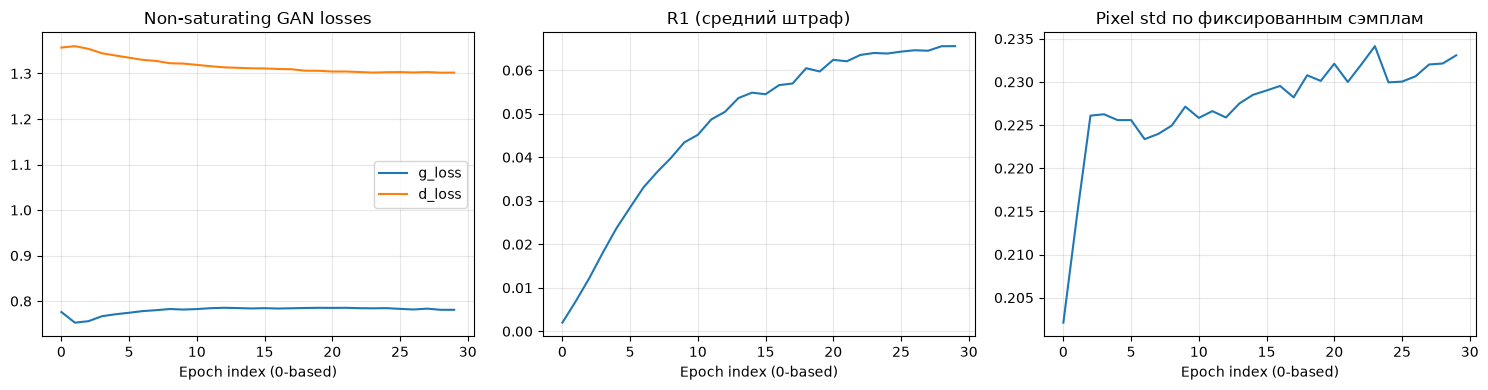

In [5]:
G = StyleGenerator(latent_dim_gan,w_dim,num_channels).to(device)
D = StyleDiscriminator(num_channels).to(device)
with torch.no_grad():
    z_check = torch.randn(4,latent_dim_gan,device=device)
    ws_check = G.make_ws(z_check)
    img_check = G(z_check)
    assert G.num_ws >= 4 and G.mapping(z_check).shape == (4,w_dim)
    assert ws_check.shape == (4,G.num_ws,w_dim)
    assert img_check.shape == (4,num_channels,image_size,image_size)
    assert D(img_check).shape == (4,1)
    assert torch.allclose(img_check,G.forward_from_ws(ws_check))
    assert -1 <= img_check.min() <= img_check.max() <= 1
# Проверяем, что все стилевые входы действительно влияют на синтез.
ws_grad = ws_check.detach().requires_grad_(True)
style_grad = torch.autograd.grad(G.forward_from_ws(ws_grad).square().mean(),ws_grad)[0]
assert (style_grad.square().sum((0,2)) > 0).all()
print('Интерфейс и градиенты всех',G.num_ws,'стилевых входов проверены.')
print('G parameters:',sum(p.numel() for p in G.parameters()))
print('D parameters:',sum(p.numel() for p in D.parameters()))
G_ema = copy.deepcopy(G).eval().requires_grad_(False)
optimizer_G = optim.Adam(G.parameters(),lr=1e-3,betas=(0.0,0.99),fused=device.type=='cuda')
optimizer_D = optim.Adam(D.parameters(),lr=1e-3,betas=(0.0,0.99),fused=device.type=='cuda')
num_epochs_gan = 30
amp_enabled = device.type == 'cuda'
r1_gamma, r1_interval, style_mixing_prob, ema_half_life = 1.0, 16, 0.9, 10000
fixed_z = torch.randn(32,latent_dim_gan,generator=torch.Generator().manual_seed(SEED+1)).to(device)
config = dict(seed=SEED,image_size=image_size,z_dim=latent_dim_gan,w_dim=w_dim,
              num_ws=G.num_ws,batch_size=batch_size,epochs=num_epochs_gan,
              g_lr=1e-3,d_lr=1e-3,adam_betas=[0,0.99],r1_gamma=r1_gamma,
              r1_interval=r1_interval,style_mixing_prob=style_mixing_prob,
              ema_half_life_images=ema_half_life,precision='bfloat16 autocast; float32 R1',train_size=len(dataset),
              steps_per_epoch=len(dataloader),log_dir=log_dir_stylegan)
(result_dir/'config.json').write_text(json.dumps(config,indent=2))
writer_gan.add_text('config',json.dumps(config,indent=2))
writer_gan.add_graph(G,z_check)

def discriminator_loss(real_logits,fake_logits):
    return F.softplus(-real_logits).mean()+F.softplus(fake_logits).mean()
def generator_loss(fake_logits):
    return F.softplus(-fake_logits).mean()
def augment(x):
    flip = torch.rand(x.shape[0],1,1,1,device=x.device)<0.5
    return torch.where(flip,x.flip(-1),x)
def training_styles(n):
    ws = G.make_ws(torch.randn(n,latent_dim_gan,device=device))
    if random.random()<style_mixing_prob:
        ws2 = G.make_ws(torch.randn(n,latent_dim_gan,device=device))
        cutoff = random.randrange(1,G.num_ws)
        ws = torch.cat([ws[:,:cutoff],ws2[:,cutoff:]],dim=1)
    return ws

global_step, seen_images, history, start_epoch = 0,0,[],0
if resume_state is not None:
    for key in ['image_size','z_dim','w_dim','batch_size']:
        assert resume_state['config'][key] == config[key], key
    G.load_state_dict(resume_state['G']); D.load_state_dict(resume_state['D'])
    G_ema.load_state_dict(resume_state['G_ema'])
    for optimizer,key in [(optimizer_G,'optimizer_G'),(optimizer_D,'optimizer_D')]:
        saved_opt = resume_state[key]
        for group in saved_opt['param_groups']:
            group['fused'] = device.type == 'cuda'; group['foreach'] = False
        optimizer.load_state_dict(saved_opt)
    start_epoch,global_step,seen_images = resume_state['epoch'],resume_state['global_step'],resume_state['seen_images']
    history = resume_state['history']
    fixed_z = resume_state['fixed_z'].to(device)
    torch.set_rng_state(resume_state['torch_rng_state'])
    if device.type == 'cuda': torch.cuda.set_rng_state_all(resume_state['cuda_rng_states'])
    random.setstate(resume_state['python_rng_state']); np.random.set_state(resume_state['numpy_rng_state'])
    loader_generator.set_state(resume_state['loader_rng_state'])
    config['resumed_after_epoch'] = start_epoch
    resume_state = None
    print('Веса, оптимизаторы, EMA и RNG восстановлены; следующий epoch:',start_epoch+1)

# Компиляция меняет только исполнение; веса и классы сохраняются обычными state_dict.
def synthesis_training(ws):
    return G.forward_from_ws(ws,noise_mode='random')
use_compile = device.type == 'cuda' and os.environ.get('STYLEGAN_COMPILE','1') == '1'
synthesize_train = torch.compile(synthesis_training,mode='default',dynamic=False) if use_compile else synthesis_training
discriminate_train = torch.compile(D.forward,mode='default',dynamic=False) if use_compile else D.forward
config.update(compiled_training=use_compile,optimizer_fused=device.type=='cuda')
(result_dir/'config.json').write_text(json.dumps(config,indent=2))
started = time.time()
for epoch in range(start_epoch,num_epochs_gan):
    G.train(); D.train()
    epoch_started = time.time()
    sums = torch.zeros(5,device=device)
    for real_images,_ in dataloader:
        real = real_images.to(device,non_blocking=True)
        n = real.shape[0]
        D.requires_grad_(True)
        optimizer_D.zero_grad(set_to_none=True)
        do_r1 = global_step % r1_interval == 0
        real.requires_grad_(False)
        with torch.no_grad(), torch.autocast(device_type=device.type,dtype=torch.bfloat16,enabled=amp_enabled):
            fake = synthesize_train(training_styles(n))
        with torch.autocast(device_type=device.type,dtype=torch.bfloat16,enabled=amp_enabled):
            real_logits, fake_logits = discriminate_train(augment(real)),discriminate_train(augment(fake))
        loss_d_main = discriminator_loss(real_logits.float(),fake_logits.float())
        r1 = torch.zeros((),device=device)
        if do_r1:
            # R1 и его вторые производные вычисляются отдельно в float32.
            r1_real = real.detach().requires_grad_(True)
            r1_logits = D(augment(r1_real))
            real_grad = torch.autograd.grad(r1_logits.sum(),r1_real,create_graph=True)[0]
            r1 = real_grad.square().flatten(1).sum(1).mean()
        # Интервал компенсирует редкое вычисление штрафа; шаг D остаётся один на батч.
        loss_d = loss_d_main + (r1_gamma/2)*r1_interval*r1
        if not torch.isfinite(loss_d): raise FloatingPointError('D loss is not finite')
        loss_d.backward(); optimizer_D.step()

        D.requires_grad_(False)
        optimizer_G.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type,dtype=torch.bfloat16,enabled=amp_enabled):
            ws = training_styles(n)
            fake = synthesize_train(ws)
            g_logits = discriminate_train(augment(fake))
        loss_g = generator_loss(g_logits.float())
        if not torch.isfinite(loss_g): raise FloatingPointError('G loss is not finite')
        loss_g.backward(); optimizer_G.step()
        with torch.no_grad():
            G.w_avg.lerp_(ws.detach().float().mean((0,1)),0.01)
            seen_images += n
            half_life = min(ema_half_life,max(seen_images*0.05,1))
            decay = 0.5**(n/half_life)
            for p_ema,p in zip(G_ema.parameters(),G.parameters()): p_ema.lerp_(p.detach(),1-decay)
            for b_ema,b in zip(G_ema.buffers(),G.buffers()): b_ema.copy_(b)
        sums += torch.stack([loss_g.detach(),loss_d_main.detach(),r1.detach()*r1_interval,
                             (real_logits.detach()>0).float().mean(),(fake_logits.detach()<0).float().mean()])
        if global_step%100==0:
            writer_gan.add_scalar('step/g_loss',loss_g.item(),global_step)
            writer_gan.add_scalar('step/d_loss',loss_d_main.item(),global_step)
            if do_r1: writer_gan.add_scalar('step/r1',r1.item(),global_step)
        global_step += 1
    values = (sums/len(dataloader)).cpu().tolist()
    G.eval(); D.eval()
    with torch.no_grad():
        samples = (G_ema(fixed_z)+1).clamp(0,2)/2
        valid_real_accuracy = (D(valid_images)>0).float().mean().item()
        diversity_std = samples.std(0).mean().item()
    row = dict(epoch=epoch+1,g_loss=values[0],d_loss=values[1],r1=values[2],
               train_real_accuracy=values[3],fake_accuracy=values[4],
               valid_real_accuracy=valid_real_accuracy,sample_pixel_std=diversity_std,
               seconds=time.time()-epoch_started,global_step=global_step,seen_images=seen_images)
    history.append(row)
    for key,value in row.items():
        if key!='epoch': writer_gan.add_scalar('epoch/'+key,value,epoch+1)
    writer_gan.add_images('samples/fixed_z_ema',samples[:16],epoch+1)
    save_image(samples,result_dir/f'epoch_{epoch+1:03d}.png',nrow=8)
    state = dict(G=G.state_dict(),D=D.state_dict(),G_ema=G_ema.state_dict(),
                 optimizer_G=optimizer_G.state_dict(),optimizer_D=optimizer_D.state_dict(),
                 epoch=epoch+1,global_step=global_step,seen_images=seen_images,config=config,
                 history=history,fixed_z=fixed_z.cpu(),torch_rng_state=torch.get_rng_state(),
                 cuda_rng_states=torch.cuda.get_rng_state_all(),python_rng_state=random.getstate(),
                 numpy_rng_state=np.random.get_state(),loader_rng_state=loader_generator.get_state())
    tmp = checkpoint_dir/'training_last.pth.tmp'
    torch.save(state,tmp); tmp.replace(checkpoint_dir/'training_last.pth')
    if (epoch+1)%5==0:
        torch.save(G_ema.state_dict(),checkpoint_dir/f'G_ema_epoch_{epoch+1:03d}.pth')
        torch.save(D.state_dict(),checkpoint_dir/f'D_epoch_{epoch+1:03d}.pth')
    (result_dir/'history.json').write_text(json.dumps(history,indent=2))
    writer_gan.flush()
    print(f"Epoch {epoch+1:02d}/{num_epochs_gan}: G={values[0]:.3f} D={values[1]:.3f} "
          f"R1={values[2]:.3f} diversity={diversity_std:.3f} {row['seconds']:.1f}s",flush=True)

D.requires_grad_(True)
torch.save(dict(model_state_dict=G_ema.state_dict(),config=config,epoch=num_epochs_gan,
                description='EMA generator; last epoch, no test-based selection'),checkpoint_dir/'stylegan_G_final.pth')
torch.save(dict(model_state_dict=D.state_dict(),config=config,epoch=num_epochs_gan),checkpoint_dir/'stylegan_D_final.pth')
# Все демонстрации используют те же финальные EMA-веса, которые сдаём.
G = G_ema
G.eval()
print(f'Обучение завершено: {global_step} шагов, {(time.time()-started)/60:.1f} мин.')
fig,axes = plt.subplots(1,3,figsize=(15,4))
for key in ['g_loss','d_loss']: axes[0].plot([h[key] for h in history],label=key)
axes[0].legend(); axes[0].set_title('Non-saturating GAN losses')
axes[1].plot([h['r1'] for h in history]); axes[1].set_title('R1 (средний штраф)')
axes[2].plot([h['sample_pixel_std'] for h in history]); axes[2].set_title('Pixel std по фиксированным сэмплам')
for ax in axes: ax.set_xlabel('Epoch index (0-based)'); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(result_dir/'learning_curves.png',dpi=150); plt.show()


In [6]:
# После обучения используем полную точность для сравнения разных размеров батча.
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
print('Финальная генерация и проверки: float32, TF32 отключён.')


Финальная генерация и проверки: float32, TF32 отключён.


### Часть B. Шаг 5: Генерация изображений и интерполяция

Что сделать: сгенерировать галерею изображений, показать интерполяцию между двумя латентными векторами, залогировать результаты в TensorBoard.

Ожидается: осмысленные изображения и плавная интерполяция.

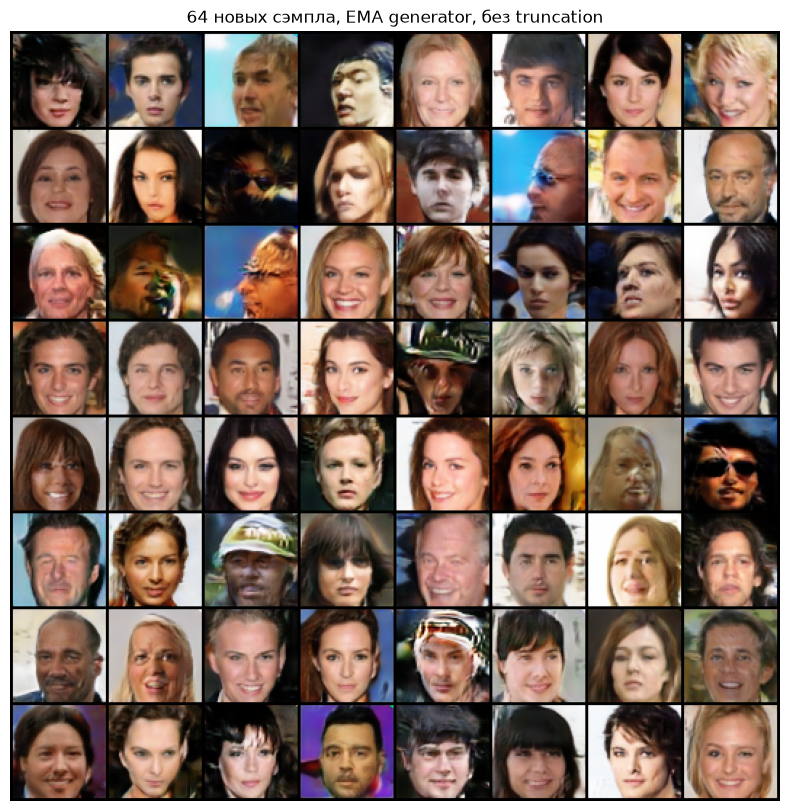

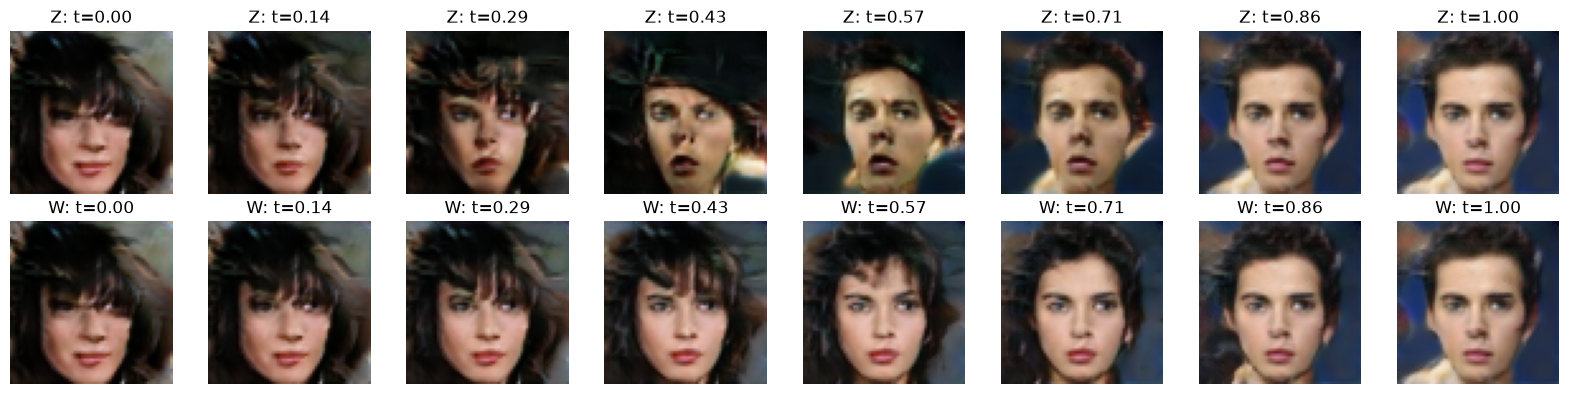

{
  "generated_pair_rms": 0.35789334774017334,
  "real_pair_rms": 0.3315753936767578,
  "interpolation_z_adjacent_rms": [
    0.204212948679924,
    0.20809321105480194,
    0.333804190158844,
    0.3599693179130554,
    0.23708829283714294,
    0.18663348257541656,
    0.10969211906194687
  ],
  "epochs": 30,
  "global_step": 38130,
  "seen_images": 4880640,
  "training_minutes": 37.71723449230194,
  "diagnostic_note": "Pixel RMS is a diversity diagnostic, not FID and not proof against mode collapse."
}
Галерея, отдельные PNG и обе интерполяции сохранены и залогированы.


In [7]:
G.eval()
# Новые случайные коды; seed не подбирается по качеству картинок.
sample_rng = torch.Generator().manual_seed(SEED+100)
num_gen = 64
z_sample = torch.randn(num_gen,latent_dim_gan,generator=sample_rng).to(device)
with torch.no_grad(): gen_images = G(z_sample)
gen_vis = ((gen_images+1)/2).clamp(0,1).cpu()
save_image(gen_vis,result_dir/'generated_gallery.png',nrow=8)
(result_dir/'generated').mkdir(exist_ok=True)
for i,img in enumerate(gen_vis): save_image(img,result_dir/'generated'/f'{i:03d}.png')
plt.figure(figsize=(10,10)); plt.imshow(make_grid(gen_vis,nrow=8).permute(1,2,0))
plt.axis('off'); plt.title('64 новых сэмпла, EMA generator, без truncation'); plt.show()
writer_gan.add_images('final/gallery',gen_vis,global_step)

num_steps_interp = 8
z1,z2 = z_sample[:1],z_sample[1:2]
t = torch.linspace(0,1,num_steps_interp,device=device)[:,None]
with torch.no_grad():
    z_interp = (1-t)*z1+t*z2
    z_interp_images = G(z_interp)
    w1,w2 = G.mapping(z1),G.mapping(z2)
    w_interp = (1-t)*w1+t*w2
    w_interp_images = G.forward_from_ws(w_interp[:,None,:].repeat(1,G.num_ws,1))
    assert torch.allclose(z_interp_images[:1],G(z1),atol=2e-5)
    assert torch.allclose(z_interp_images[-1:],G(z2),atol=2e-5)
fig,axes = plt.subplots(2,num_steps_interp,figsize=(16,4))
for row,images in enumerate([z_interp_images,w_interp_images]):
    for i,ax in enumerate(axes[row]):
        ax.imshow(((images[i].cpu()+1)/2).clamp(0,1).permute(1,2,0)); ax.axis('off')
        ax.set_title(f'{"Z" if row==0 else "W"}: t={t[i].item():.2f}')
plt.tight_layout(); plt.savefig(result_dir/'interpolation.png',dpi=160); plt.show()
writer_gan.add_images('final/interpolation_z',(z_interp_images+1).clamp(0,2)/2,global_step)
writer_gan.add_images('final/interpolation_w',(w_interp_images+1).clamp(0,2)/2,global_step)
with torch.no_grad():
    generated_pair_rms = (torch.pdist(gen_vis.flatten(1))/math.sqrt(gen_vis[0].numel())).mean().item()
    real_vis = ((valid_images[:64].cpu()+1)/2).clamp(0,1)
    real_pair_rms = (torch.pdist(real_vis.flatten(1))/math.sqrt(real_vis[0].numel())).mean().item()
    interpolation_adjacent_rms = (z_interp_images[1:]-z_interp_images[:-1]).square().mean((1,2,3)).sqrt().cpu().tolist()
metrics = dict(generated_pair_rms=generated_pair_rms,real_pair_rms=real_pair_rms,
               interpolation_z_adjacent_rms=interpolation_adjacent_rms,
               epochs=num_epochs_gan,global_step=global_step,seen_images=seen_images,
               training_minutes=sum(h['seconds'] for h in history)/60,
               diagnostic_note='Pixel RMS is a diversity diagnostic, not FID and not proof against mode collapse.')
(result_dir/'metrics.json').write_text(json.dumps(metrics,indent=2))
torch.save(dict(z=z_sample.cpu(),ws=G.make_ws(z_sample).detach().cpu(),
                interpolation_z=z_interp.cpu(),interpolation_w=w_interp.cpu()),result_dir/'generation_latents.pt')
print(json.dumps(metrics,indent=2))
print('Галерея, отдельные PNG и обе интерполяции сохранены и залогированы.')


Получились ли результаты похожими на настоящие лица?

Действительно ли интерполяция плавно приближает одно лицо к другому?

Не случилось ли Mode Collapse у вашей модели?

Мы не ожидаем идеальных результатов, но ориентиром может служить наш пример:

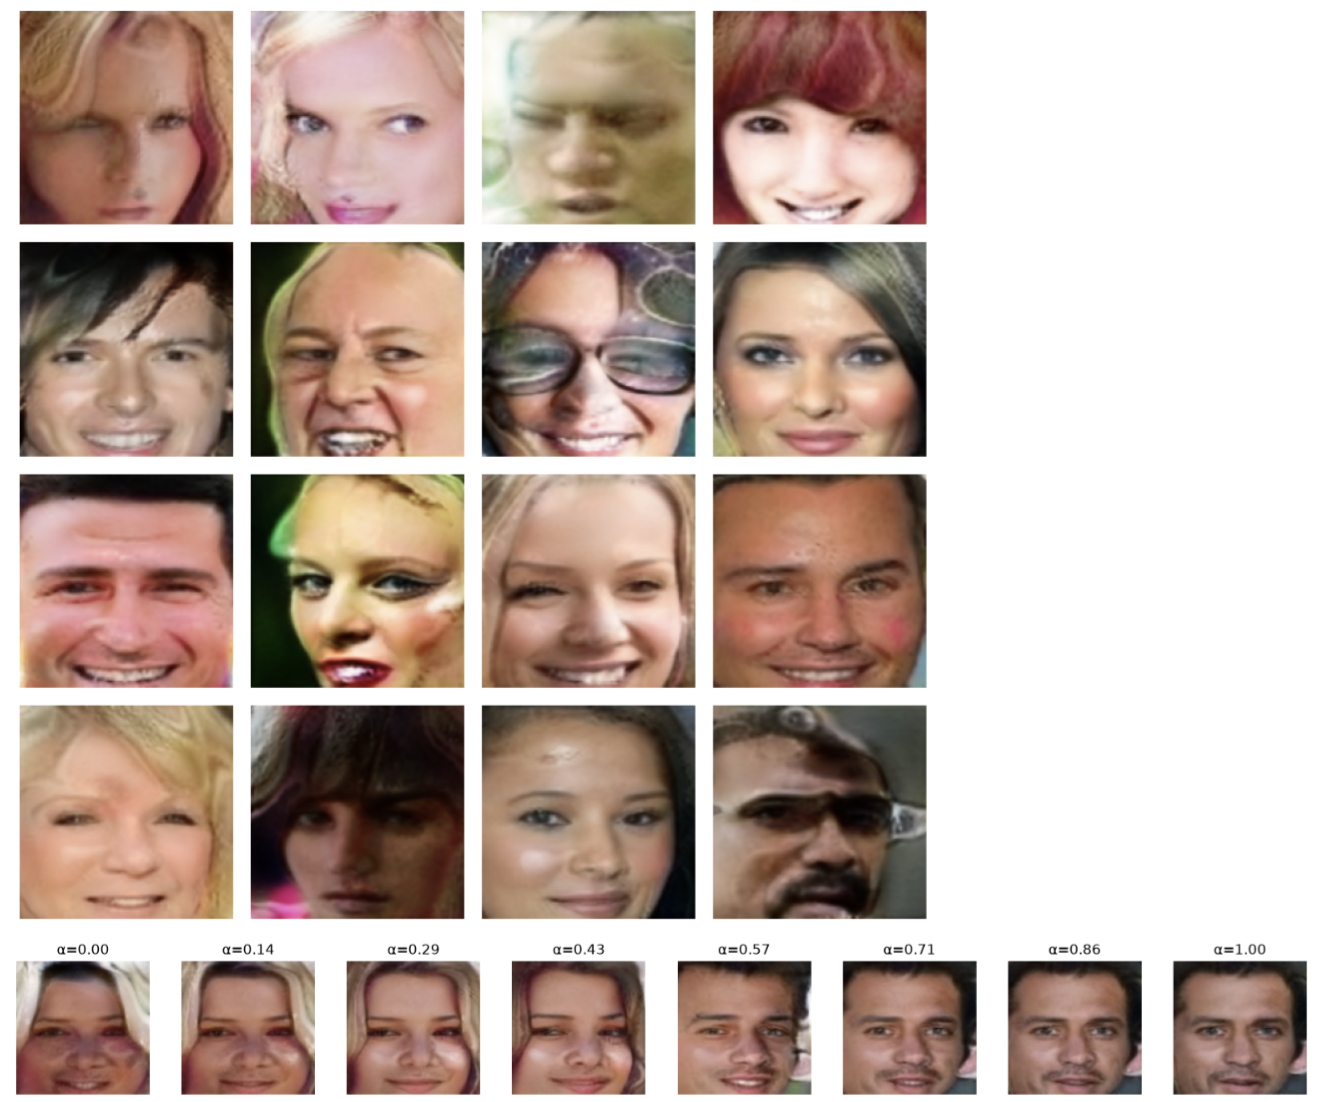

Для улучшения своих результатов мы советуем 
- поэкспериментировать с архитектурами StyleGAN-а,
- применять разные техники регуляризации,
- штрафовать модель за снижение разнообразия сэмплов,
- попробовать перечитать оригинальную статью и взять идеи оттуда: Karras et al., 2018. A Style-Based Generator Architecture for Generative Adversarial Networks. https://arxiv.org/abs/1812.04948

**Разбор собственных результатов.** В новой случайной галерее узнаваемы лица, разные ракурсы, причёски и выражения; встречаются деформированные глаза, рот и пятна на коже или волосах. В интерполяции оба конца совпадают с исходными сэмплами: переход в Z неравномерен и сильнее меняется в середине, а в показанном примере W выглядит плавнее. В галерее из 64 сэмплов явного полного mode collapse не наблюдается, однако это не доказывает полное покрытие распределения. Средний попарный pixel RMS составляет 0.358 для сгенерированных и 0.332 для реальных изображений; это только диагностика разнообразия, FID не рассчитывался.


### Часть B. Шаг 6: Style mixing (комбинирование стилей)

Что сделать: продемонстрировать style mixing (упрощённый вариант) между двумя латентными кодами.

Ожидается: примеры изображений с сочетанием признаков от разных кодов.

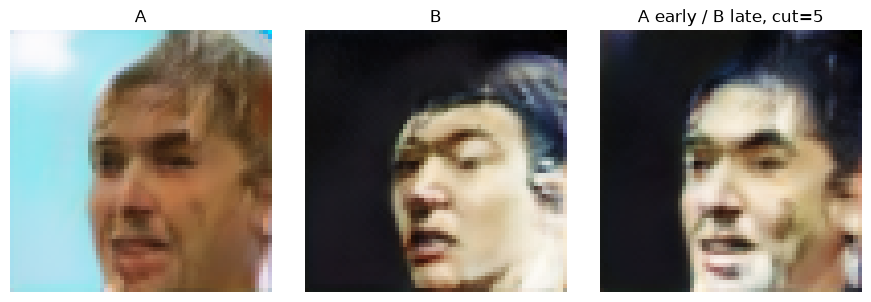

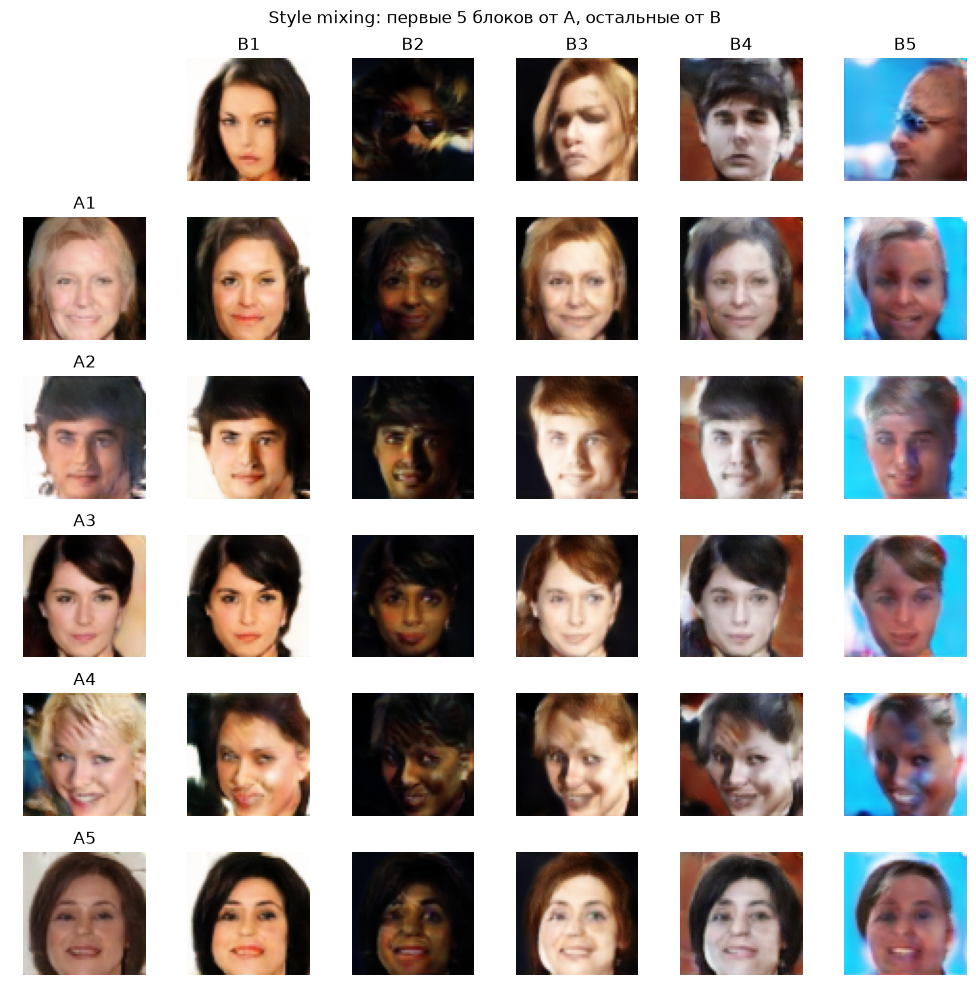

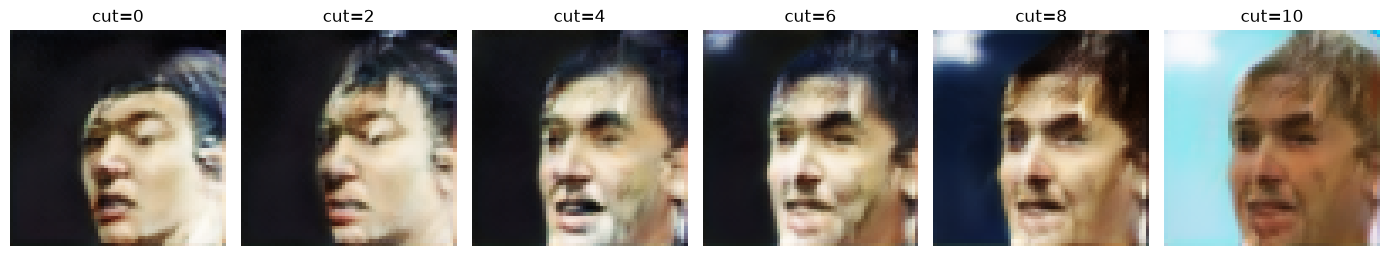

Style mixing проверен, сохранён и записан в TensorBoard. Шум фиксирован: изменяются только стили.


In [8]:
G.eval()
z_a,z_b = z_sample[2:3],z_sample[3:4]
with torch.no_grad():
    ws_a,ws_b = G.make_ws(z_a),G.make_ws(z_b)
    crossover = G.num_ws//2
    ws_mix = torch.cat([ws_a[:,:crossover],ws_b[:,crossover:]],dim=1)
    img_a,img_b,img_mix = G.forward_from_ws(ws_a),G.forward_from_ws(ws_b),G.forward_from_ws(ws_mix)
    # Граничные случаи: все стили от B / все стили от A.
    assert torch.allclose(G.forward_from_ws(torch.cat([ws_a[:,:0],ws_b],1)),img_b)
    assert torch.allclose(G.forward_from_ws(torch.cat([ws_a,ws_b[:,G.num_ws:]],1)),img_a)
    assert (img_mix-img_a).abs().mean()>1e-6 and (img_mix-img_b).abs().mean()>1e-6
fig,axes = plt.subplots(1,3,figsize=(9,3))
for ax,img,title in zip(axes,[img_a,img_b,img_mix],['A','B',f'A early / B late, cut={crossover}']):
    ax.imshow(((img[0].cpu()+1)/2).clamp(0,1).permute(1,2,0)); ax.axis('off'); ax.set_title(title)
plt.tight_layout(); plt.savefig(result_dir/'style_mixing_pair.png',dpi=160); plt.show()

# Матрица: строки задают ранние стили, столбцы — поздние.
rows,cols = z_sample[4:9],z_sample[9:14]
with torch.no_grad():
    row_ws,col_ws = G.make_ws(rows),G.make_ws(cols)
    row_images,col_images = G(rows),G(cols)
    mixed = torch.stack([G.forward_from_ws(torch.cat([
        row_ws[i:i+1,:crossover].repeat(5,1,1),col_ws[:,crossover:]],dim=1)) for i in range(5)])
fig,axes = plt.subplots(6,6,figsize=(10,10))
for ax in axes.flat: ax.axis('off')
for j in range(5):
    axes[0,j+1].imshow(((col_images[j].cpu()+1)/2).clamp(0,1).permute(1,2,0)); axes[0,j+1].set_title(f'B{j+1}')
for i in range(5):
    axes[i+1,0].imshow(((row_images[i].cpu()+1)/2).clamp(0,1).permute(1,2,0)); axes[i+1,0].set_title(f'A{i+1}')
    for j in range(5): axes[i+1,j+1].imshow(((mixed[i,j].cpu()+1)/2).clamp(0,1).permute(1,2,0))
plt.suptitle(f'Style mixing: первые {crossover} блоков от A, остальные от B')
plt.tight_layout(); plt.savefig(result_dir/'style_mixing_matrix.png',dpi=160); plt.show()

cutoffs = [0,2,4,6,8,10]
with torch.no_grad():
    cut_images = torch.cat([G.forward_from_ws(torch.cat([ws_a[:,:c],ws_b[:,c:]],1)) for c in cutoffs])
fig,axes = plt.subplots(1,len(cutoffs),figsize=(14,3))
for ax,img,c in zip(axes,cut_images,cutoffs):
    ax.imshow(((img.cpu()+1)/2).clamp(0,1).permute(1,2,0)); ax.axis('off'); ax.set_title(f'cut={c}')
plt.tight_layout(); plt.savefig(result_dir/'style_mixing_cutoffs.png',dpi=160); plt.show()
writer_gan.add_images('final/style_mixing_pair',(torch.cat([img_a,img_b,img_mix])+1).clamp(0,2)/2,global_step)
writer_gan.add_images('final/style_mixing_matrix',(mixed.flatten(0,1)+1).clamp(0,2)/2,global_step)
writer_gan.add_images('final/style_mixing_cutoffs',(cut_images+1).clamp(0,2)/2,global_step)
torch.save(dict(z_a=z_a.cpu(),z_b=z_b.cpu(),ws_a=ws_a.cpu(),ws_b=ws_b.cpu(),
                ws_mix=ws_mix.cpu(),crossover=crossover,noise_mode='const'),result_dir/'style_mixing_latents.pt')
print('Style mixing проверен, сохранён и записан в TensorBoard. Шум фиксирован: изменяются только стили.')


В качестве референса можно использовать этот пример:

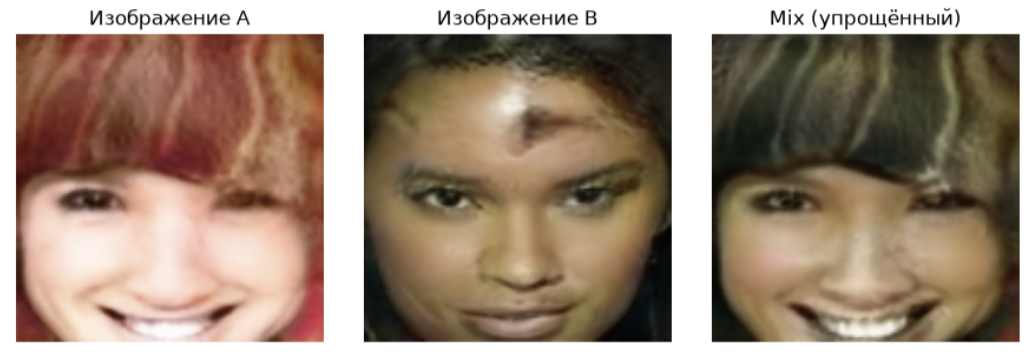

### Часть B. Шаг 7: Текстовое описание pipeline

Что сделать: кратко описать (1-2 абзаца), как вы реализовали и обучили StyleGAN-подобную модель, какие гиперпараметры использовали и какие результаты получили. Какие возникали сложности и как вы их решили, к каким источникам обращались в процессе.

Ожидается: понятное описание всей цепочки (данные - модель - обучение - визуализация)

Использован официальный train CelebA: квадратный crop 140, resize до 64×64 и нормализация в [−1,1]. Модель реализована своими классами PyTorch: mapping из четырёх полносвязных слоёв переводит нормализованный z∈R¹²⁸ в w∈R¹²⁸; синтез начинается с обучаемой константы 4×4 и содержит 10 StyledBlock на разрешениях 4–64. В каждом блоке свой affine(w) задаёт scale/bias AdaIN; обучаемый шум отвечает за стохастические детали. Дискриминатор использует остаточные блоки с понижением разрешения и minibatch-stddev. Основные проходы выполняются с bfloat16 autocast на A100, R1 — в float32. Обучение: 30 эпох, batch=128, Adam lr=0.001, betas=(0,0.99), non-saturating logistic loss, R1 gamma=1 каждые 16 шагов с компенсацией интервала. Style mixing используется с вероятностью 0.9; EMA с half-life 10 000 изображений сглаживает изменения генератора. Тестовые изображения не участвуют в обучении, сохранена последняя эпоха без выбора по test.

Демонстрации выполнены финальным EMA-генератором: случайная галерея без truncation, линейные интерполяции в Z и W, матрица style mixing и разные положения crossover. В сравнении смешивания шум зафиксирован, поэтому эффект связан со сменой стилевых входов. Основные риски GAN — неустойчивость и потеря разнообразия; для них применены R1, minibatch-stddev, EMA и наблюдение за одной фиксированной галереей по эпохам. Pixel RMS используется только как диагностика разнообразия, а не как FID или доказательство отсутствия mode collapse. Идеи mapping/AdaIN/noise/style mixing взяты из [Karras et al., A Style-Based Generator Architecture](https://arxiv.org/abs/1812.04948), R1 — из [Mescheder et al., Which Training Methods for GANs do actually Converge?](https://arxiv.org/abs/1801.04406). Готовые реализации и предобученные веса не использовались. После 30 эпох выполнено 38,130 шагов и 4,880,640 предъявлений изображений; сумма времени эпох — 37.7 мин. Матрица mixing показывает перенос цвета, освещения и волос от поздних стилей, но одновременно может менять идентичность: полного разделения признаков не получено. Для финальных демонстраций TF32 отключён, поскольку сравнение разных размеров батча требует полной точности float32. Это упрощённая модель: без progressive growing, modulated convolution StyleGAN2 и path-length regularization.


In [9]:
writer_gan.add_text('conclusion','Собственная StyleGAN-like модель; финальный EMA-генератор, интерполяции Z/W и style mixing.',global_step)
writer_gan.flush(); writer_gan.close()
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
acc = EventAccumulator(log_dir_stylegan,size_guidance={'images':1}); acc.Reload()
assert len(acc.Scalars('epoch/g_loss')) == num_epochs_gan
assert {'final/gallery','final/interpolation_z','final/style_mixing_matrix'} <= set(acc.Tags()['images'])
assert acc.Tags()['graph']
restored_G = StyleGenerator(latent_dim_gan,w_dim,num_channels).to(device).eval()
restored_D = StyleDiscriminator(num_channels).to(device).eval()
g_ckpt = torch.load(checkpoint_dir/'stylegan_G_final.pth',map_location=device,weights_only=False)
d_ckpt = torch.load(checkpoint_dir/'stylegan_D_final.pth',map_location=device,weights_only=False)
restored_G.load_state_dict(g_ckpt['model_state_dict']); restored_D.load_state_dict(d_ckpt['model_state_dict'])
with torch.no_grad():
    assert torch.allclose(restored_G(z_sample[:4]),G(z_sample[:4]),atol=1e-6)
    assert torch.allclose(restored_D(img_check),D(img_check),atol=1e-6)
assert len(list((result_dir/'generated').glob('*.png'))) == 64
assert all(math.isfinite(value) for row in history for value in row.values())
report = dict(executed_epochs=num_epochs_gan,global_step=global_step,
              generator_reload=True,discriminator_reload=True,
              tensorboard_graph=True,tensorboard_images=acc.Tags()['images'],
              tensorboard_scalars=acc.Tags()['scalars'],generated_pngs=64,
              style_input_gradients_verified=True,style_mixing_endpoints_verified=True)
(result_dir/'verification.json').write_text(json.dumps(report,indent=2))
print(json.dumps(report,indent=2))
print('Все итоговые файлы и TensorBoard проверены.')


Detected out of order event.step likely caused by a TensorFlow restart. Purging expired events from Tensorboard display between the previous step: -1 (timestamp: -1) and current step: 3813 (timestamp: 1795652112.4863832). Removing 14 scalars, 0 histograms, 0 compressed histograms, 0 images, and 0 audio.


Found more than one graph event per run, or there was a metagraph containing a graph_def, as well as one or more graph events.  Overwriting the graph with the newest event.


Found more than one "run metadata" event with tag step1. Overwriting it with the newest event.


{
  "executed_epochs": 30,
  "global_step": 38130,
  "generator_reload": true,
  "discriminator_reload": true,
  "tensorboard_graph": true,
  "tensorboard_images": [
    "samples/fixed_z_ema",
    "final/gallery",
    "final/interpolation_z",
    "final/interpolation_w",
    "final/style_mixing_pair",
    "final/style_mixing_matrix",
    "final/style_mixing_cutoffs"
  ],
  "tensorboard_scalars": [
    "step/g_loss",
    "step/d_loss",
    "step/r1",
    "epoch/g_loss",
    "epoch/d_loss",
    "epoch/r1",
    "epoch/train_real_accuracy",
    "epoch/fake_accuracy",
    "epoch/valid_real_accuracy",
    "epoch/sample_pixel_std",
    "epoch/seconds",
    "epoch/global_step",
    "epoch/seen_images"
  ],
  "generated_pngs": 64,
  "style_input_gradients_verified": true,
  "style_mixing_endpoints_verified": true
}
Все итоговые файлы и TensorBoard проверены.
